# HalfCheetah (medium data): BC, IQL and online fine-tuning

Planar locomotion task: a two-legged robot is rewarded for forward velocity. Dataset: Minari `mujoco/halfcheetah/medium-v0`.

## Problem formulation

| | |
|---|---|
| **State** $s \in \mathbb{R}^{17}$ | 8 joint positions (torso height and angle, 6 joint angles; the forward position is excluded) and 9 velocities |
| **Action** $a \in [-1, 1]^{6}$ | torques of the back and front thigh, shin and foot joints |
| **Reward** | $r = \dot x - 0.1\,\lVert a \rVert^2$ |
| **Termination** | none; episodes are truncated at 1,000 steps |
| **Discount** | $\gamma = 0.99$ |

## Dataset
1,000,000 transitions (1,000 episodes) from a TQC agent trained for $6 \times 10^6$ steps (Minari documentation: "runs fast, in a natural looking motion, while never falling over"). Despite the name, the behavior policy is close to expert level and the data is generated by a single policy.

**Reward scaling.** As in the official IQL implementation, training rewards are multiplied by $1000 / (R_{\max} - R_{\min})$, where $R_{\max}$ and $R_{\min}$ are the largest and smallest episode returns in the dataset. Evaluation reports unscaled returns.

## Evaluation protocol
Episodes start from the default pose with small random noise, as in data collection. During training: `eval_episodes` episodes per seed every `eval_every` steps, with fixed environment seeds.

**Metrics.** Episode return $R = \sum_t r_t$ (unscaled) and `pct_data`, the return as a percentage of the dataset's mean episode return. Minari's MuJoCo datasets provide no random or expert reference returns, so the D4RL normalized score is not reported. The final evaluation also reports the fraction of episodes that terminated early (`fell`) and that stopped moving (`stuck`: average forward speed below 0.5 m/s over the last 100 steps).

## Offline RL setting
Offline reinforcement learning: the policy is learned from a fixed dataset $\mathcal{D} = \{(s, a, r, s', d)\}$ collected by an unknown behavior policy, without interaction with the environment. The environment is used for evaluation only. Value estimates are reliable only for actions represented in $\mathcal{D}$; the methods below avoid querying the critic on out-of-distribution actions.

## Usage
1. Copy the project folder (`offline-rl-jax/`) to Google Drive, e.g. `MyDrive/offline-rl-jax`.
2. Open this notebook in Colab with a GPU runtime (`Runtime → Change runtime type → T4 GPU`).
3. Set `PROJECT_DIR` in Section 1 if the folder is elsewhere, then run all cells.

Outputs are written to the project folder: `results/<name>/` (JSON and figures, tracked by git) and `checkpoints/<name>/` (network weights, not tracked).

`RUN_OFFLINE` (Section 2): `True` runs Part 1 and Part 2; `False` loads `checkpoints/<name>/offline.pkl` and runs Part 2 only.

## 1. Setup
Mounts Google Drive, sets the working directory and installs the simulator and dataset packages (JAX is preinstalled on Colab).

In [1]:
import os, sys, shutil
PROJECT_DIR = "/content/drive/MyDrive/offline-rl-jax"      # the project folder you uploaded to Google Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:                                        # running locally instead of Colab
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
if shutil.which("nvidia-smi"):
    os.environ["MUJOCO_GL"] = "egl"                        # headless rendering (only needed for videos)
print("project folder:", PROJECT_DIR)

Mounted at /content/drive
project folder: /content/drive/MyDrive/offline-rl-jax


In [2]:
!pip install -q -r requirements-colab.txt

In [3]:
import numpy as np
import jax
import matplotlib.pyplot as plt
for _m in [m for m in sys.modules if m == "offrl" or m.startswith("offrl.")]:
    del sys.modules[_m]           # always use the code currently in PROJECT_DIR (not a copy cached by an earlier run)
import offrl
from offrl import (Task, Normalizer, to_device, train_offline, EnvPool, evaluate, evaluate_final, summarize,
                   load_config, save_checkpoint, load_checkpoint, save_json, load_json, select_seed)
from offrl.algos.finetune import finetune
from offrl import plotting
print("offrl", offrl.__version__, "from", os.path.dirname(offrl.__file__))
print("JAX", jax.__version__, "| devices:", jax.devices())

offrl 0.3.0 from /content/drive/MyDrive/offline-rl-jax/offrl
JAX 0.11.1 | devices: [CudaDevice(id=0)]


## 2. Settings
Hyperparameters are read from `configs/halfcheetah_medium.yaml`. With `RUN_OFFLINE = False`, `cfg` is taken from the checkpoint so that it matches the saved networks; `ONLINE` is always read from the config file.

In [4]:
CONFIG_FILE = "configs/halfcheetah_medium.yaml"
RUN_OFFLINE = True     # True: train offline (Part 1), save, then fine-tune. False: load the saved offline networks.

cfg, ONLINE = load_config(CONFIG_FILE)
RESULTS_DIR = f"results/{cfg['name']}"            # small files (JSON, figures), meant for GitHub
CKPT_DIR = f"checkpoints/{cfg['name']}"           # trained networks (large, ignored by git)
if not RUN_OFFLINE:
    ck = load_checkpoint(f"{CKPT_DIR}/offline.pkl")
    cfg = ck["config"]
print("offline:", cfg)
print("online: ", ONLINE)

offline: {'name': 'halfcheetah_medium', 'dataset_id': 'mujoco/halfcheetah/medium-v0', 'seeds': [0, 1, 2], 'normalize_reward': True, 'batch_size': 256, 'hidden_dim': 256, 'lr': 0.0003, 'actor_lr_schedule': 'cosine', 'bc_steps': 1500000, 'iql_steps': 1500000, 'eval_every': 50000, 'eval_episodes': 10, 'final_episodes': 20, 'episodes_per_cell': 3, 'discount': 0.99, 'tau': 0.005, 'expectile': 0.7, 'beta': 3.0, 'max_weight': 100.0}
online:  {'online_steps': 1000000, 'envs_per_seed': 4, 'chunk': 2000, 'updates_per_step': 1, 'explore_temperature': 0.3, 'reset_on_flip': False, 'eval_every': 50000, 'eval_episodes': 10, 'final_episodes': 20}


## 3. Data and evaluation environment
`Task` defines the dataset, the evaluation environment, the state representation and the transition labels. States are standardized with the dataset statistics (or those saved with the checkpoint), and the dataset is stored on the GPU. `evaluate_fn` is the evaluation used during training (fixed environment seeds, mean action).

In [5]:
task = Task(cfg)
raw = task.transitions()
normalizer = Normalizer(raw["states"]) if RUN_OFFLINE else Normalizer.from_state_dict(ck["normalizer"])
DATA = to_device(raw, normalizer)
pool = EnvPool(task)
N_SEEDS = len(cfg["seeds"])
print("state dim:", DATA["s"].shape[1], "| action dim:", DATA["a"].shape[1])

def evaluate_fn(pi):      # the test used during training: deterministic policy mean, eval_episodes per seed
    return evaluate(task, pi, N_SEEDS, cfg["eval_episodes"], 1000, pool, normalizer)

namespace_metadata.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

metadata.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/3.26k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/3.62k [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


Dataset mujoco/halfcheetah/medium-v0 downloaded to /root/.minari/datasets/mujoco/halfcheetah/medium-v0


/usr/local/lib/python3.13/dist-packages/minari/dataset/minari_dataset.py:204: UserWarning: Installed mujoco version 3.2.6 does not meet the requirement ==3.2.3.
We recommend to install the required version with `pip install "mujoco==3.2.3"`
  warnings.warn(


task: mujoco/halfcheetah/medium-v0 (mujoco) | 1,000 episodes, 1,000,000 steps | test episodes: 1000 steps | metric: return
1,000,000 transitions | reward scale 0.0714 | terminal in 0 of them (0.00%)
state dim: 17 | action dim: 6


Distribution of episode returns in the dataset.

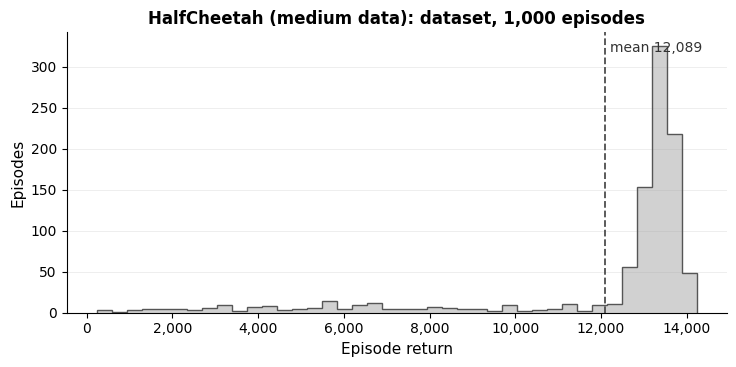

In [6]:
plotting.plot_dataset_returns(task, save_path=f"{RESULTS_DIR}/figures/dataset_returns.png")

# Part 1: Offline training

## 4. Methods

Both methods train a policy $\pi_\theta(a \mid s)$ on $\mathcal{D}$. All networks are MLPs with two hidden layers of `hidden_dim` units and ReLU activations; the policy mean is passed through $\tanh$ to the action range $[-1, 1]$.

### Behavior cloning (BC)
Regression of the dataset action (`offrl/algos/bc.py`):
$$\mathcal{L}_{BC}(\theta) = \mathbb{E}_{(s,a)\sim\mathcal{D}}\big[\,\lVert \mu_\theta(s) - a \rVert^2\,\big]$$
BC imitates the behavior policy and does not use rewards.

### Implicit Q-Learning (IQL)
Kostrikov, Nair and Levine, *Offline Reinforcement Learning with Implicit Q-Learning*, ICLR 2022 ([arXiv:2110.06169](https://arxiv.org/abs/2110.06169)); `offrl/algos/iql.py`. Three networks are updated on each batch.

**State value** by expectile regression on the target Q-values of dataset actions:
$$\mathcal{L}_V(\psi) = \mathbb{E}_{(s,a)\sim\mathcal{D}}\Big[\,L_2^{\tau}\big(\hat Q(s,a) - V_\psi(s)\big)\Big], \qquad L_2^{\tau}(u) = \lvert \tau - \mathbf{1}(u<0)\rvert\, u^2, \qquad \hat Q = \min(Q_{\bar\phi_1}, Q_{\bar\phi_2})$$
For $\tau = 0.5$ this is mean regression; for $\tau > 0.5$ (`expectile`), $V(s)$ approaches the upper range of the Q-values of in-distribution actions, an in-sample estimate of $\max_a Q(s,a)$.

**Action value** by temporal-difference learning with $V(s')$ in place of $\max_{a'} Q(s',a')$:
$$\mathcal{L}_Q(\phi_i) = \mathbb{E}_{(s,a,r,s',d)\sim\mathcal{D}}\Big[\big(r + \gamma\,(1-d)\,V_\psi(s') - Q_{\phi_i}(s,a)\big)^2\Big], \quad i = 1, 2$$
Two critics are used; their target networks are updated as $\bar\phi \leftarrow (1-\tau_t)\bar\phi + \tau_t\phi$ with $\tau_t$ = `tau`. Terminal flags $d = 1$ mark true terminations only, not time limits.

**Policy** by advantage-weighted regression:
$$\mathcal{L}_\pi(\theta) = -\,\mathbb{E}_{(s,a)\sim\mathcal{D}}\Big[\min\big(e^{\beta\,(\hat Q(s,a) - V_\psi(s))},\ 100\big)\,\log \pi_\theta(a \mid s)\Big]$$
Dataset actions are weighted by their exponentiated advantage $A = \hat Q - V$; $\beta$ (`beta`) controls the selectivity ($\beta \to 0$ recovers BC). The policy is Gaussian, $\mathcal{N}(\mu_\theta(s), \sigma^2)$, with a learned state-independent $\sigma$; evaluation uses the mean action $\mu_\theta(s)$. The policy learning rate follows a cosine decay over `iql_steps`.

Hyperparameters (config file): `expectile` ($\tau$), `beta` ($\beta$), `discount` ($\gamma$), `tau` (target update rate), `lr`, `batch_size`, `hidden_dim`.

### Training
Seeds are trained in parallel (`jax.vmap`); each block of `eval_every` updates is compiled as one program (`jax.lax.scan`). `train` in the log is training time excluding evaluation; the first block includes compilation. For IQL the log reports the TD loss `q_loss` and the batch mean of $V(s)$.

### 4a. Behavior cloning

In [7]:
if RUN_OFFLINE:
    bc_states, bc_log = train_offline("bc", cfg, DATA, evaluate_fn)

/usr/local/lib/python3.13/dist-packages/minari/dataset/minari_dataset.py:204: UserWarning: Installed mujoco version 3.2.6 does not meet the requirement ==3.2.3.
We recommend to install the required version with `pip install "mujoco==3.2.3"`
  warnings.warn(


[BC ] step    50,000 | loss 0.0833 | return [10692 9138 3900] (mean 7910) | pct_data [88.4 75.6 32.3] (mean 65.4) | train 14s, total 18s
[BC ] step   100,000 | loss 0.0715 | return [13593 15075 7262] (mean 11977) | pct_data [112.4 124.7 60.1] (mean 99.1) | train 25s, total 33s
[BC ] step   150,000 | loss 0.0690 | return [12939 13552 13620] (mean 13371) | pct_data [107.0 112.1 112.7] (mean 110.6) | train 37s, total 48s
[BC ] step   200,000 | loss 0.0677 | return [13556 6483 11032] (mean 10357) | pct_data [112.1 53.6 91.3] (mean 85.7) | train 49s, total 63s
[BC ] step   250,000 | loss 0.0669 | return [13491 15343 12483] (mean 13772) | pct_data [111.6 126.9 103.3] (mean 113.9) | train 61s, total 78s
[BC ] step   300,000 | loss 0.0664 | return [12705 12063 14406] (mean 13058) | pct_data [105.1 99.8 119.2] (mean 108.0) | train 73s, total 93s
[BC ] step   350,000 | loss 0.0659 | return [14899 13705 14023] (mean 14209) | pct_data [123.2 113.4 116.0] (mean 117.5) | train 86s, total 109s
[BC ] 

### 4b. Implicit Q-Learning

In [8]:
if RUN_OFFLINE:
    iql_states, iql_log = train_offline("iql", cfg, DATA, evaluate_fn)

[IQL] step    50,000 | q_loss 1.175 | V    58.58 | return [1970 363 2954] (mean 1762) | pct_data [16.3 3.0 24.4] (mean 14.6) | train 64s, total 68s
[IQL] step   100,000 | q_loss 2.362 | V    90.15 | return [644 2043 2437] (mean 1708) | pct_data [5.3 16.9 20.2] (mean 14.1) | train 121s, total 128s
[IQL] step   150,000 | q_loss 2.430 | V    91.77 | return [5780 4490 7350] (mean 5873) | pct_data [47.8 37.1 60.8] (mean 48.6) | train 178s, total 190s
[IQL] step   200,000 | q_loss 2.360 | V    91.64 | return [4062 8536 4389] (mean 5662) | pct_data [33.6 70.6 36.3] (mean 46.8) | train 236s, total 250s
[IQL] step   250,000 | q_loss 2.321 | V    91.47 | return [7732 8554 5050] (mean 7112) | pct_data [64.0 70.8 41.8] (mean 58.8) | train 293s, total 310s
[IQL] step   300,000 | q_loss 2.232 | V    91.30 | return [6042 6776 8526] (mean 7115) | pct_data [50.0 56.1 70.5] (mean 58.9) | train 350s, total 371s
[IQL] step   350,000 | q_loss 2.167 | V    91.21 | return [8251 9305 10032] (mean 9196) | pct_

## 5. Offline results
Final evaluation: `final_episodes` episodes per seed with the mean action. Saved to `results/<name>/`.
- **Training curves and final test.** Mean over seeds with a ±1 std band; bars show mean ± std over seeds. Dashed line: mean episode return of the dataset.
- **Episode outcomes.** Return of every final-test episode; episodes that terminated (fall) or stopped moving (stuck) are marked. Right: episode lengths if any episode terminated, otherwise the return distribution.
- **Trajectories.** Five test episodes per method (trained seed 0) and five dataset episodes: forward position, forward velocity and torso height over time.
- **Filmstrips.** Eight frames of one test episode per method (requires rendering).

mujoco/halfcheetah/medium-v0  (3 seeds, 20 test episodes per seed)
method                           return             pct_data                 fell                stuck
BC                      14,454 ± 700          119.6 ± 5.8           0.00 ± 0.00          0.07 ± 0.05  
IQL                     13,915 ± 315          115.1 ± 2.6           0.00 ± 0.00          0.02 ± 0.02  
saved results/halfcheetah_medium/offline_results.json


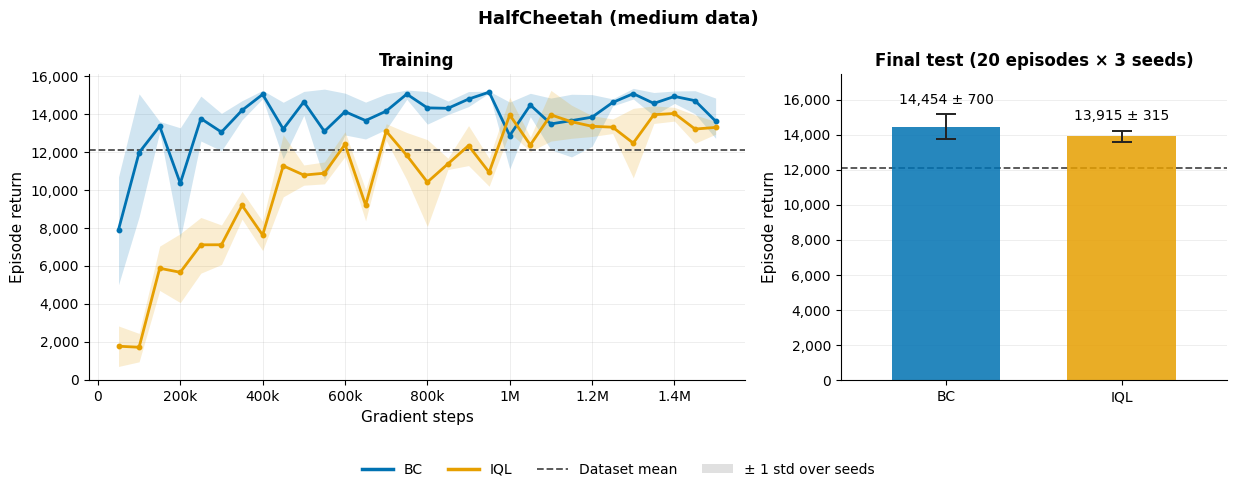

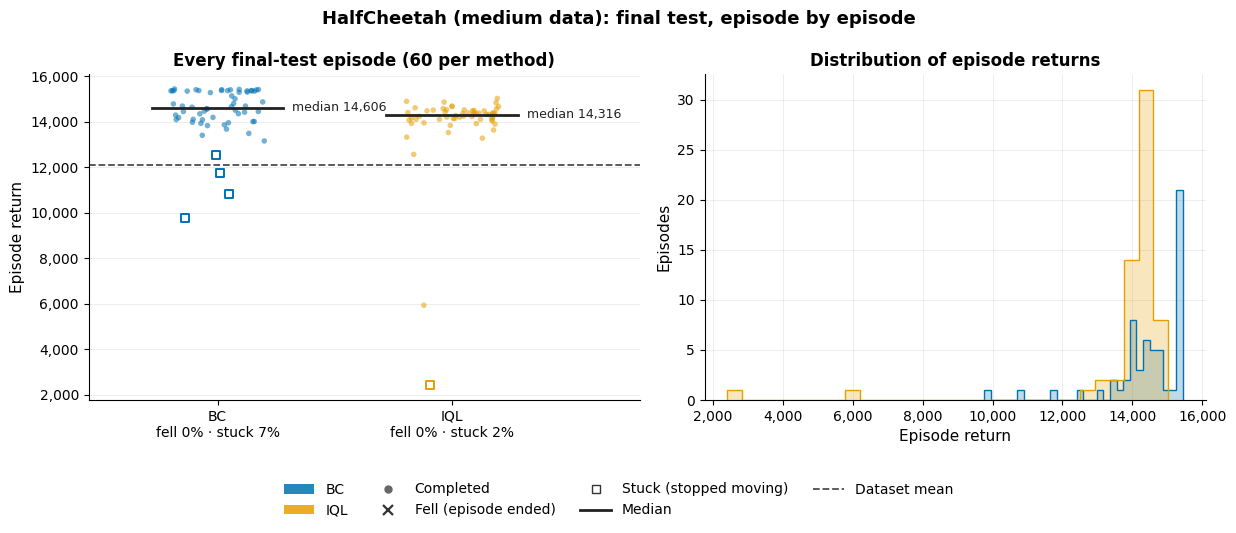

In [9]:
if RUN_OFFLINE:
    offline_res = evaluate_final(task, cfg, {"BC": bc_states, "IQL": iql_states}, {"BC": bc_log, "IQL": iql_log},
                                 pool, normalizer)
    summarize(offline_res)
    save_json(f"{RESULTS_DIR}/offline_results.json", offline_res)
    plotting.plot_offline_results(offline_res, save_path=f"{RESULTS_DIR}/figures/offline.png")
    plotting.plot_episode_outcomes(offline_res, save_path=f"{RESULTS_DIR}/figures/offline_episodes.png")

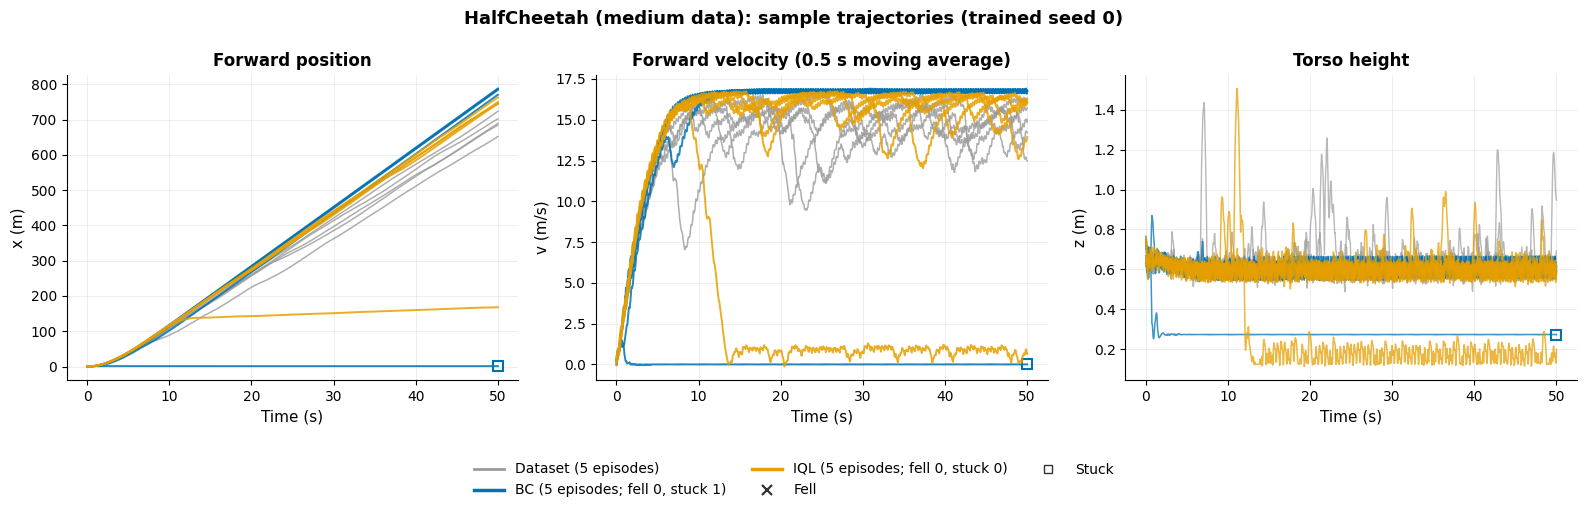

In [22]:
if RUN_OFFLINE:
    plotting.plot_mujoco_trajectories(task, {"BC": bc_states, "IQL": iql_states}, pool, normalizer,
                                      save_path=f"{RESULTS_DIR}/figures/offline_trajectories.png")

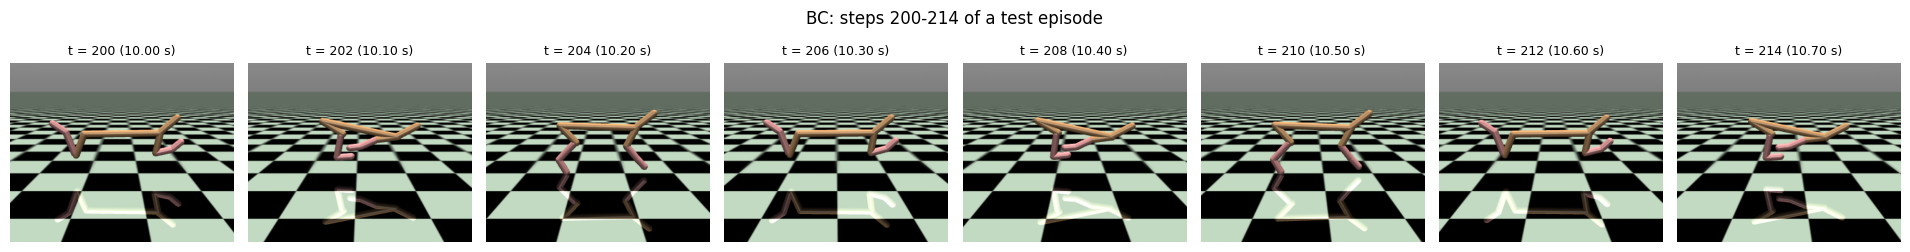

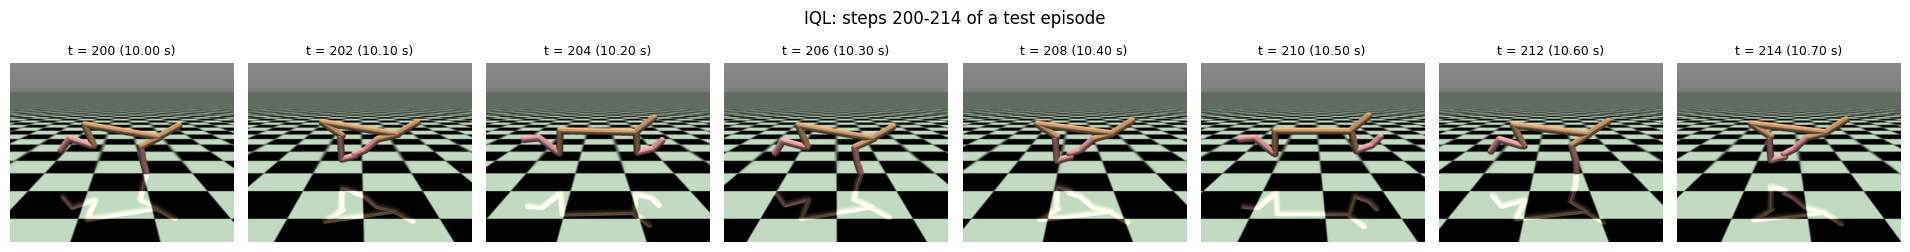

In [17]:
if RUN_OFFLINE:
    from offrl.video import plot_filmstrip
    try:
        for name, st in {"BC": bc_states, "IQL": iql_states}.items():
            plot_filmstrip(task, st, normalizer, title=name, save_path=f"{RESULTS_DIR}/figures/offline_filmstrip_{name.replace(' ', '_')}.png")
    except Exception as e:                      # rendering needs a GPU runtime on Colab (MUJOCO_GL=egl)
        print("Rendering is not available here:", e)

## 6. Checkpoint
Saves the configuration, the state normalizer and the BC and IQL networks (including optimizer states) to `checkpoints/<name>/offline.pkl`.

In [23]:
if RUN_OFFLINE:
    save_checkpoint(f"{CKPT_DIR}/offline.pkl", config=cfg, online=ONLINE, normalizer=normalizer.state_dict(),
                    bc_states=bc_states, iql_states=iql_states)

saved checkpoints/halfcheetah_medium/offline.pkl (14.7 MB)


# Part 2: Online fine-tuning

The offline IQL networks are trained further with environment interaction, using the same losses (`offrl/algos/finetune.py`, following the official IQL implementation):

- **Data collection.** `envs_per_seed` environments per seed; actions $a = \operatorname{clip}\big(\mu_\theta(s) + T\,\sigma\,\varepsilon,\ -1,\ 1\big)$, $\varepsilon \sim \mathcal{N}(0, I)$, with $T$ = `explore_temperature`.
- **Labels.** Online transitions are labeled exactly as the offline data.
- **Replay.** One buffer per seed containing $\mathcal{D}_{\text{offline}} \cup \mathcal{D}_{\text{online}}$, sampled uniformly.
- **Optimization.** One update per environment step (`updates_per_step`); optimizers are re-initialized with a constant learning rate.

The log reports the evaluation metrics every `eval_every` online steps (step 0 is the offline policy) and statistics of the exploration episodes (`explore`). Checkpoints are written to `checkpoints/<name>/finetuned.pkl` after each evaluation.

## 7. Initialization from the offline IQL networks

In [24]:
if not RUN_OFFLINE:
    iql_states = ck["iql_states"]
offline_iql = iql_states
print("starting fine-tuning from:", "memory (Part 1)" if RUN_OFFLINE else f"{CKPT_DIR}/offline.pkl")
print("online settings:", ONLINE)

starting fine-tuning from: memory (Part 1)
online settings: {'online_steps': 1000000, 'envs_per_seed': 4, 'chunk': 2000, 'updates_per_step': 1, 'explore_temperature': 0.3, 'reset_on_flip': False, 'eval_every': 50000, 'eval_episodes': 10, 'final_episodes': 20}


## 8. Fine-tuning
Evaluation metrics during fine-tuning (mean over seeds, ±1 std band); step 0 is the offline policy.

[FT] online step         0 | return [13619 13496 12803] (mean 13306) | pct_data [112.7 111.6 105.9] (mean 110.1) | explore: - | 3s
[FT] online step    50,000 | return [9358 7797 11990] (mean 9715) | pct_data [77.4 64.5 99.2] (mean 80.4) | explore: 144 episodes, return 7815.1 | q_loss 1.949 V    88.75 | 104s
saved checkpoints/halfcheetah_medium/finetuned.pkl (12.1 MB)
[FT] online step   100,000 | return [14950 6391 6768] (mean 9370) | pct_data [123.7 52.9 56.0] (mean 77.5) | explore: 156 episodes, return 9239.8 | q_loss 2.261 V    87.68 | 202s
saved checkpoints/halfcheetah_medium/finetuned.pkl (12.1 MB)
[FT] online step   150,000 | return [15054 13396 12413] (mean 13621) | pct_data [124.5 110.8 102.7] (mean 112.7) | explore: 144 episodes, return 9553.7 | q_loss 2.227 V    86.87 | 296s
saved checkpoints/halfcheetah_medium/finetuned.pkl (12.1 MB)
[FT] online step   200,000 | return [13498 12223 12916] (mean 12879) | pct_data [111.7 101.1 106.8] (mean 106.5) | explore: 156 episodes, return

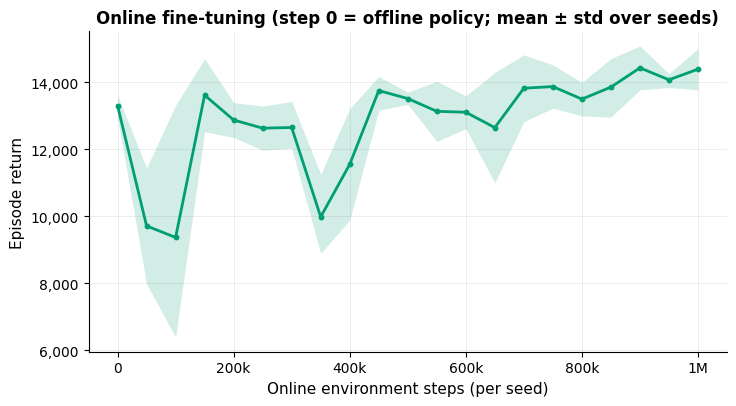

In [18]:
def save_progress(states, log):          # called after every evaluation
    save_checkpoint(f"{CKPT_DIR}/finetuned.pkl", config=cfg, online=ONLINE, normalizer=normalizer.state_dict(),
                    iql_states=states, log=log)

ft_states, ft_log = finetune(task, cfg, ONLINE, offline_iql, DATA, pool, normalizer, on_eval=save_progress)
save_json(f"{RESULTS_DIR}/finetune_log.json", ft_log)
plotting.plot_finetune(ft_log, list(task.curve_metrics), save_path=f"{RESULTS_DIR}/figures/finetune_curves.png")

### Offline and online learning curve
IQL evaluation metric over offline training followed by fine-tuning (shaded; one environment step corresponds to one gradient step). Reference lines: final BC result and dataset mean return. The offline curve is read from `results/<name>/offline_results.json`.

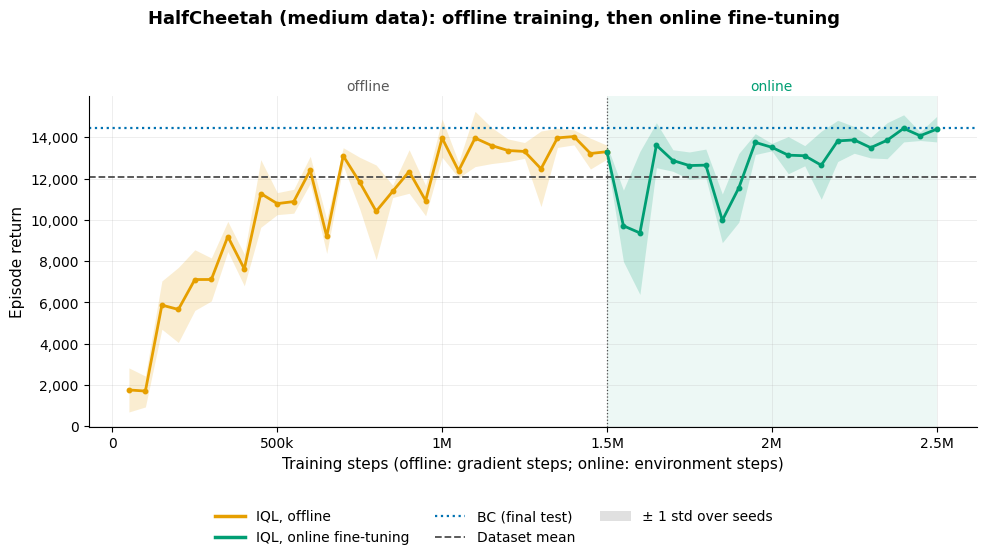

In [25]:
off_res = offline_res if RUN_OFFLINE else load_json(f"{RESULTS_DIR}/offline_results.json")
bc_final = float(np.mean([r["final"][task.primary] for r in off_res["methods"]["BC"]]))
refs = {task.primary: {"BC (final test)": bc_final}}
if task.kind == "mujoco":
    refs[task.primary]["dataset mean"] = task.data_return
plotting.plot_offline_online(off_res, ft_log, list(task.curve_metrics), refs=refs,
                             save_path=f"{RESULTS_DIR}/figures/offline_to_online.png")

## 9. Offline and fine-tuned policies
Final evaluation of both policies on the same episodes, with the figures of Section 5.

mujoco/halfcheetah/medium-v0  (3 seeds, 20 test episodes per seed)
method                           return             pct_data                 fell                stuck
offline IQL             13,915 ± 315          115.1 ± 2.6           0.00 ± 0.00          0.02 ± 0.02  
fine-tuned IQL          14,246 ± 868          117.8 ± 7.2           0.00 ± 0.00          0.02 ± 0.02  
saved results/halfcheetah_medium/finetune_results.json


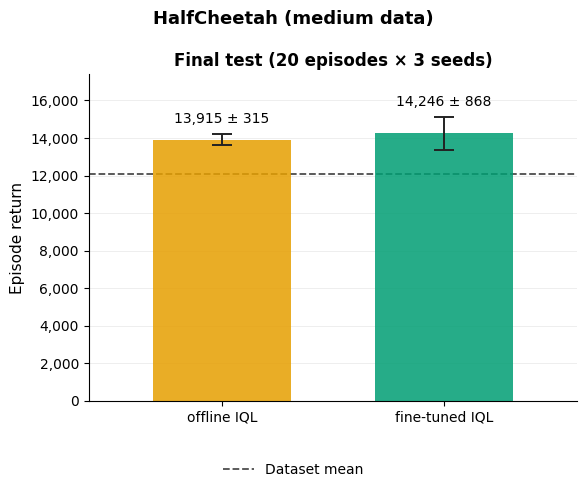

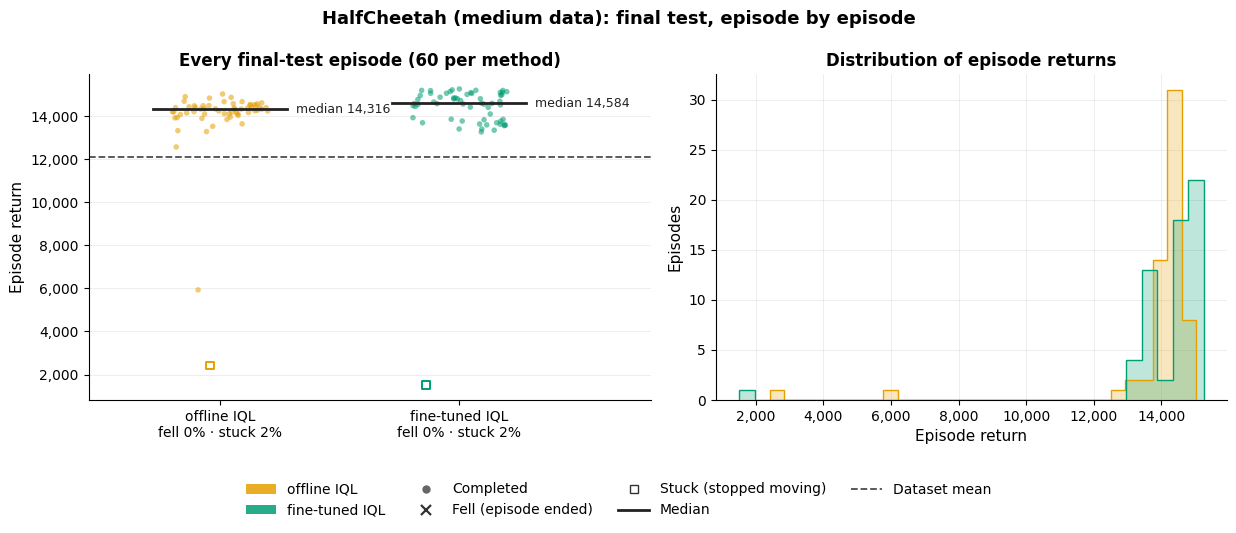

In [26]:
ft_res = evaluate_final(task, {**cfg, "final_episodes": ONLINE["final_episodes"]},
                        {"offline IQL": offline_iql, "fine-tuned IQL": ft_states}, None, pool, normalizer)
summarize(ft_res)
save_json(f"{RESULTS_DIR}/finetune_results.json", ft_res)
plotting.plot_offline_results(ft_res, save_path=f"{RESULTS_DIR}/figures/finetune_final.png")
plotting.plot_episode_outcomes(ft_res, save_path=f"{RESULTS_DIR}/figures/finetune_episodes.png")

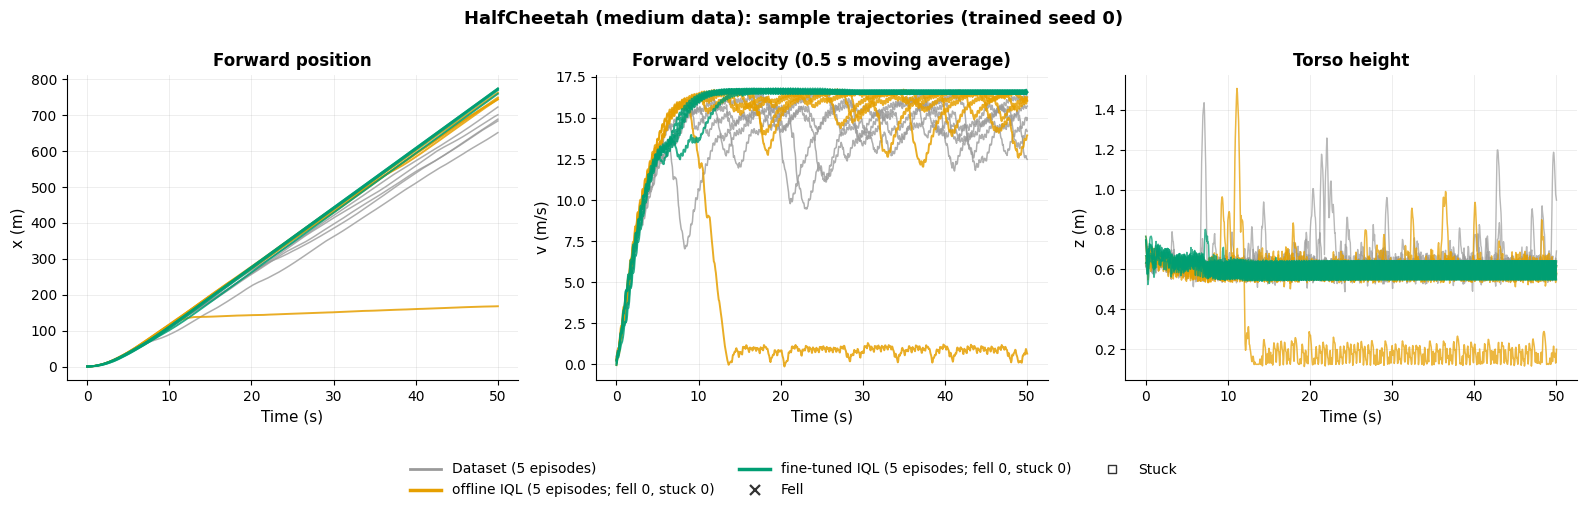

In [27]:
plotting.plot_mujoco_trajectories(task, {"offline IQL": offline_iql, "fine-tuned IQL": ft_states}, pool, normalizer,
                                  save_path=f"{RESULTS_DIR}/figures/finetune_trajectories.png")

/usr/local/lib/python3.13/dist-packages/minari/dataset/minari_dataset.py:204: UserWarning: Installed mujoco version 3.2.6 does not meet the requirement ==3.2.3.
We recommend to install the required version with `pip install "mujoco==3.2.3"`
  warnings.warn(


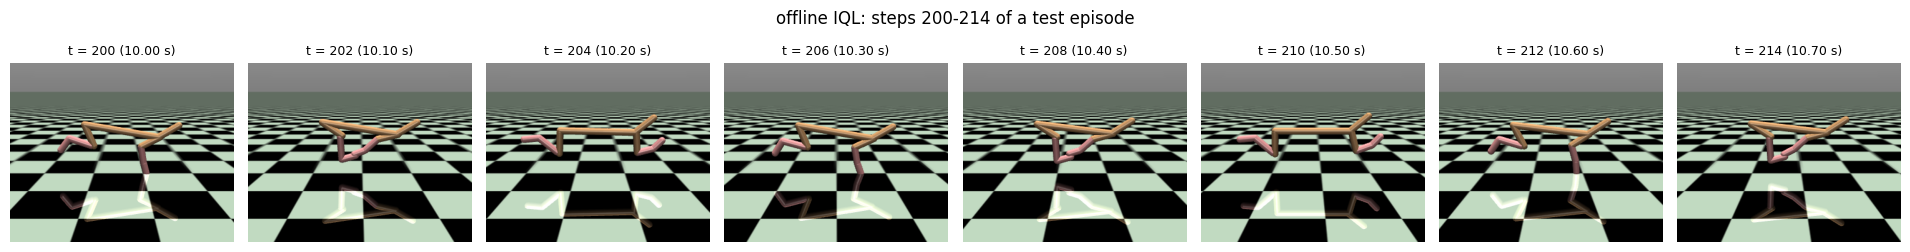

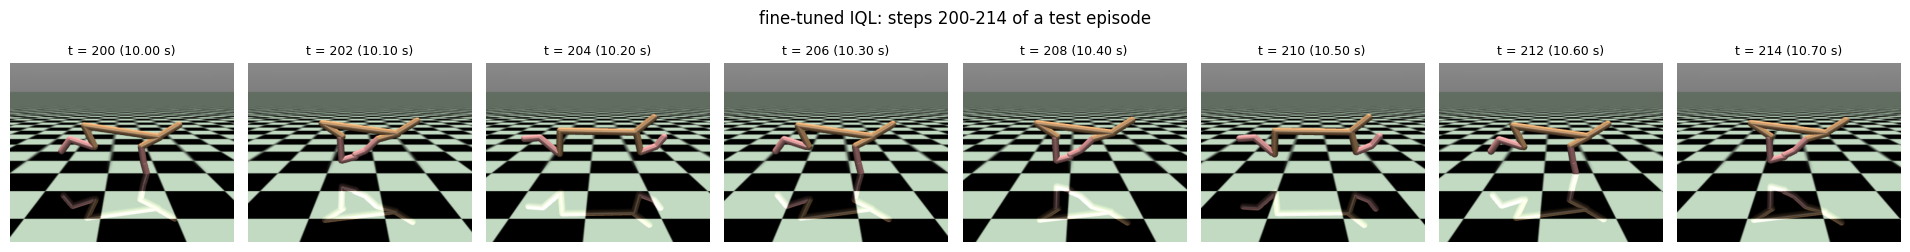

In [19]:
from offrl.video import plot_filmstrip
try:
    for name, st in {"offline IQL": offline_iql, "fine-tuned IQL": ft_states}.items():
        plot_filmstrip(task, st, normalizer, title=name, save_path=f"{RESULTS_DIR}/figures/finetune_filmstrip_{name.replace(' ', '_')}.png")
except Exception as e:                      # rendering needs a GPU runtime on Colab (MUJOCO_GL=egl)
    print("Rendering is not available here:", e)

## 10. Episode recording (optional)
Records one evaluation episode as a GIF (requires rendering). Side camera centered on the torso, approximately real time; `max_steps` and `camera_distance` adjust length and zoom. `seed_index` selects the trained seed.

In [21]:
from offrl.video import record_gif
from IPython.display import Image, display
gif_path, _ = record_gif(task, ft_states, normalizer, f"{RESULTS_DIR}/figures/fine_tuned.gif", seed_index=0)
display(Image(filename=gif_path))

time limit | return 3793.8 -> results/halfcheetah_medium/figures/fine_tuned.gif


[The animation is not stored in this notebook to keep its size small; a shortened copy is in media/halfcheetah_medium.gif.]
